# VitaStress — Classificatore ternario
Tre classi, come nel paper: **riposo** (0), **stress cognitivo e sociale** (1: calcolo + discorso), **stress fisico** (2: corsa).
Parte 1: tabella. Parte 2: sei classificatori. Parte 3: errori. Parte 4: ablation. Parte 5: rete neurale (MLP).

# Parte 1 — Tabella

## Fase 0 — Setup
Librerie, dataset ed elenco dei soggetti. `ESCLUDI`: persone da tenere fuori (nessuna). `ASSI_GIRATI`: persone con il braccialetto ruotato, a cui invertire la media di alcuni assi.

In [1]:
import os
import pandas as pd
import numpy as np

if not os.path.exists("VitaStress"):
    !git clone https://github.com/paulvincenz/VitaStress.git

DATA = "VitaStress/data"
persone = sorted([c.replace("id_", "") for c in os.listdir(DATA) if c.startswith("id_")])
print("Persone:", len(persone))

ESCLUDI = []
ASSI_GIRATI = {"ddca342b": ["accY", "accZ"]}   # braccialetto ruotato di 180° attorno all'asse X
persone = [p for p in persone if p[:8] not in ESCLUDI]
print("Persone usate:", len(persone))

Persone: 21
Persone usate: 21


## Fase 1 — Orari delle fasi
Dalle annotazioni ricava inizio e fine delle 4 fasi principali. Se il riposo dura più di 12 minuti (`a5e823ad`, 82 minuti) si tengono solo gli ultimi 10, come gli altri partecipanti.

In [2]:
fasi = {"baseline": "baseline", "cognitive": "cognitive",
        "public": "public speaking", "physical": "physical"}

def trova_orari(persona):
    cartella = DATA + "/id_" + persona + "/" + persona + "_"
    ann = pd.read_csv(cartella + "annotation.csv")
    ann["timestamp"] = pd.to_datetime(ann["timestamp"], format="mixed")
    ann["evento"] = ann["Button Name"].astype(str).str.lower().str.replace(":", "").str.strip(" []'")
    orari = {}
    for fase in fasi:
        nome = fasi[fase]
        inizio = ann[ann["evento"].str.startswith(nome + " start")]["timestamp"]
        fine = ann[ann["evento"].str.startswith(nome + " stop")]["timestamp"]
        if len(inizio) == 0 or len(fine) == 0:
            print(persona[:8], fase, "-> manca inizio o fine, salto")
            continue
        durata = (fine.iloc[0] - inizio.iloc[0]).total_seconds() / 60
        if fase == "baseline" and durata > 12:
            print(persona[:8], "-> riposo di", round(durata), "min, tengo gli ultimi 10")
            inizio = fine - pd.Timedelta("10min")
            durata = 10
        if durata <= 0 or durata > 30:
            print(persona[:8], fase, "-> durata strana:", round(durata, 1), "min, salto")
            continue
        orari[fase] = (inizio.iloc[0], fine.iloc[0])
    return orari

## Fase 2 — Segnali ogni 30 secondi
Media ogni 30 s per battito, temperatura e sudore; media, dev. standard e varianza per l'accelerometro. Per le persone in `ASSI_GIRATI` la media degli assi indicati cambia segno (deviazione standard e varianza non cambiano).

In [3]:
def leggi(cartella, file, colonna):
    dati = pd.read_csv(cartella + file + ".csv", usecols=["date", colonna])
    dati["date"] = pd.to_datetime(dati["date"], format="mixed")
    return dati.set_index("date")[colonna]

def segnali_30s(persona):
    cartella = DATA + "/id_" + persona + "/" + persona + "_"

    bpm = leggi(cartella, "activity", "bpm").replace(0, np.nan)
    temp = leggi(cartella, "temperature", "temp_sk1").replace(0, np.nan)
    sudore = leggi(cartella, "emography", "stress_skin")

    tab = pd.DataFrame({
        "bpm": bpm.resample("30s").mean(),
        "temp_sk1": temp.resample("30s").mean(),
        "stress_skin": sudore.resample("30s").mean().ffill(limit=1),
    })
    for asse in ["accX", "accY", "accZ"]:
        acc = leggi(cartella, "acc", asse).resample("30s")
        tab[asse + "_mean"] = acc.mean()
        tab[asse + "_std"] = acc.std()
        tab[asse + "_var"] = acc.var()
    for asse in ASSI_GIRATI.get(persona[:8], []):
        tab[asse + "_mean"] = -tab[asse + "_mean"]
    return tab

## Fase 3 — Fasi ed etichetta
Tiene solo i blocchi dentro una fase. Riposo = 0, calcolo + discorso = 1, corsa = 2.

In [4]:
classi = {"baseline": 0, "cognitive": 1, "public": 1, "physical": 2}
nomi_classi = ["riposo", "cognitivo", "fisico"]

def tabella_persona(persona):
    tab = segnali_30s(persona)
    orari = trova_orari(persona)
    pezzi = []
    for fase in orari:
        inizio, fine = orari[fase]
        pezzo = tab[(tab.index >= inizio) & (tab.index < fine)].copy()
        pezzo["fase"] = fase
        pezzi.append(pezzo)
    tab = pd.concat(pezzi)
    tab["persona"] = persona
    tab["classe"] = tab["fase"].map(classi)
    return tab

## Fase 4 — Tutti i soggetti
Circa 30 secondi di calcolo.

In [5]:
tabella = pd.concat([tabella_persona(p) for p in persone]).reset_index()
print("Righe:", len(tabella))
print(tabella["fase"].value_counts())

a5e823ad -> riposo di 82 min, tengo gli ultimi 10


Righe: 1190
fase
baseline     423
physical     351
public       215
cognitive    201
Name: count, dtype: int64


## Fase 5 — Dati mancanti
Percentuale di valori mancanti per colonna e fase.

In [6]:
colonne = ["bpm", "stress_skin", "temp_sk1",
           "accX_mean", "accX_std", "accX_var", "accY_mean", "accY_std", "accY_var",
           "accZ_mean", "accZ_std", "accZ_var"]

mancanti = tabella.groupby("fase")[colonne].apply(lambda t: t.isna().mean() * 100).round(1)
mancanti.T

fase,baseline,cognitive,physical,public
bpm,0.0,3.0,2.3,4.7
stress_skin,0.0,0.0,0.0,0.0
temp_sk1,0.0,0.5,0.3,0.0
accX_mean,0.0,0.0,0.0,0.0
accX_std,0.0,0.0,0.0,0.0
accX_var,0.0,0.0,0.0,0.0
accY_mean,0.0,0.0,0.0,0.0
accY_std,0.0,0.0,0.0,0.0
accY_var,0.0,0.0,0.0,0.0
accZ_mean,0.0,0.0,0.0,0.0


## Fase 6 — Pulizia e normalizzazione
Tolgo le righe incomplete e normalizzo ogni persona rispetto a sé stessa, come nel notebook 02.

In [7]:
prima = len(tabella)
tabella = tabella.dropna(subset=colonne)
print("Righe tolte:", prima - len(tabella), "-> rimaste", len(tabella))

for col in colonne:
    tabella[col] = tabella.groupby("persona")[col].transform(lambda s: (s - s.mean()) / s.std())

print(tabella["classe"].value_counts().sort_index())
tabella.to_csv("tabella_ternario_30s.csv", index=False)

Righe tolte: 25 -> rimaste 1165
classe
0    423
1    400
2    342
Name: count, dtype: int64


# Parte 2 — Sei classificatori

## Fase 7 — Feature ed etichetta
X = cosa il modello guarda, y = la classe, gruppi = la persona. Il riferimento minimo è rispondere sempre la classe più numerosa.

In [8]:
X = tabella[colonne]
y = tabella["classe"]
gruppi = tabella["persona"]

print("Righe:", len(X), "| feature:", X.shape[1])
print("Rispondendo sempre la classe più numerosa:", round(y.value_counts(normalize=True).max() * 100, 1), "%")

Righe: 1165 | feature: 12
Rispondendo sempre la classe più numerosa: 36.3 %


## Fase 8 — I sei classificatori
Gli stessi del notebook 02.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

modelli = {
    "LR": LogisticRegression(max_iter=1000),
    "RF": RandomForestClassifier(n_estimators=100, random_state=42),
    "DT": DecisionTreeClassifier(random_state=42),
    "LDA": LinearDiscriminantAnalysis(),
    "XGB": XGBClassifier(random_state=42),
    "kNN": KNeighborsClassifier(n_neighbors=5),
}

## Fase 9 — Validazione leave-one-subject-out
Addestra su tutte le persone tranne una, prova su quella, ripete per tutte. Media e deviazione standard di accuracy e F1 macro.

In [10]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import accuracy_score, f1_score

def valuta(modello, X, y, gruppi):
    acc, f1 = [], []
    for train, test in LeaveOneGroupOut().split(X, y, gruppi):
        modello.fit(X.iloc[train], y.iloc[train])
        previsto = modello.predict(X.iloc[test])
        acc.append(accuracy_score(y.iloc[test], previsto))
        f1.append(f1_score(y.iloc[test], previsto, average="macro"))
    return np.mean(acc), np.std(acc), np.mean(f1), np.std(f1)

## Fase 10 — Risultati
Una riga per classificatore, accanto alla Tabella 2 del paper (accuracy del ternario, tutte le feature).

In [11]:
paper = {"LR": 0.769, "RF": 0.772, "DT": 0.682, "LDA": 0.758, "XGB": 0.773, "kNN": 0.763}

risultati = []
for nome in modelli:
    a, a_sd, f, f_sd = valuta(modelli[nome], X, y, gruppi)
    risultati.append({"modello": nome,
                      "accuracy": f"{a:.2f} ± {a_sd:.2f}",
                      "paper": paper[nome],
                      "F1": f"{f:.2f} ± {f_sd:.2f}",
                      "acc_media": a})

risultati = pd.DataFrame(risultati)
risultati

,modello,accuracy,paper,F1,acc_media
0,LR,0.91 ± 0.08,0.769,0.91 ± 0.08,0.909595
1,RF,0.94 ± 0.06,0.772,0.94 ± 0.06,0.943981
2,DT,0.85 ± 0.10,0.682,0.84 ± 0.11,0.849001
3,LDA,0.89 ± 0.07,0.758,0.89 ± 0.07,0.894926
4,XGB,0.93 ± 0.05,0.773,0.93 ± 0.05,0.934327
5,kNN,0.88 ± 0.10,0.763,0.88 ± 0.10,0.883525


## Fase 11 — Stile
Colori e stile comuni a tutti i grafici.

In [12]:
import matplotlib.pyplot as plt

BLU, ARANCIO, GRIGIO = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.8})
VERDE = "#1baf7a"

## Fase 12 — Noi contro il paper
Accuracy media di ogni classificatore accanto a quella della Tabella 2.

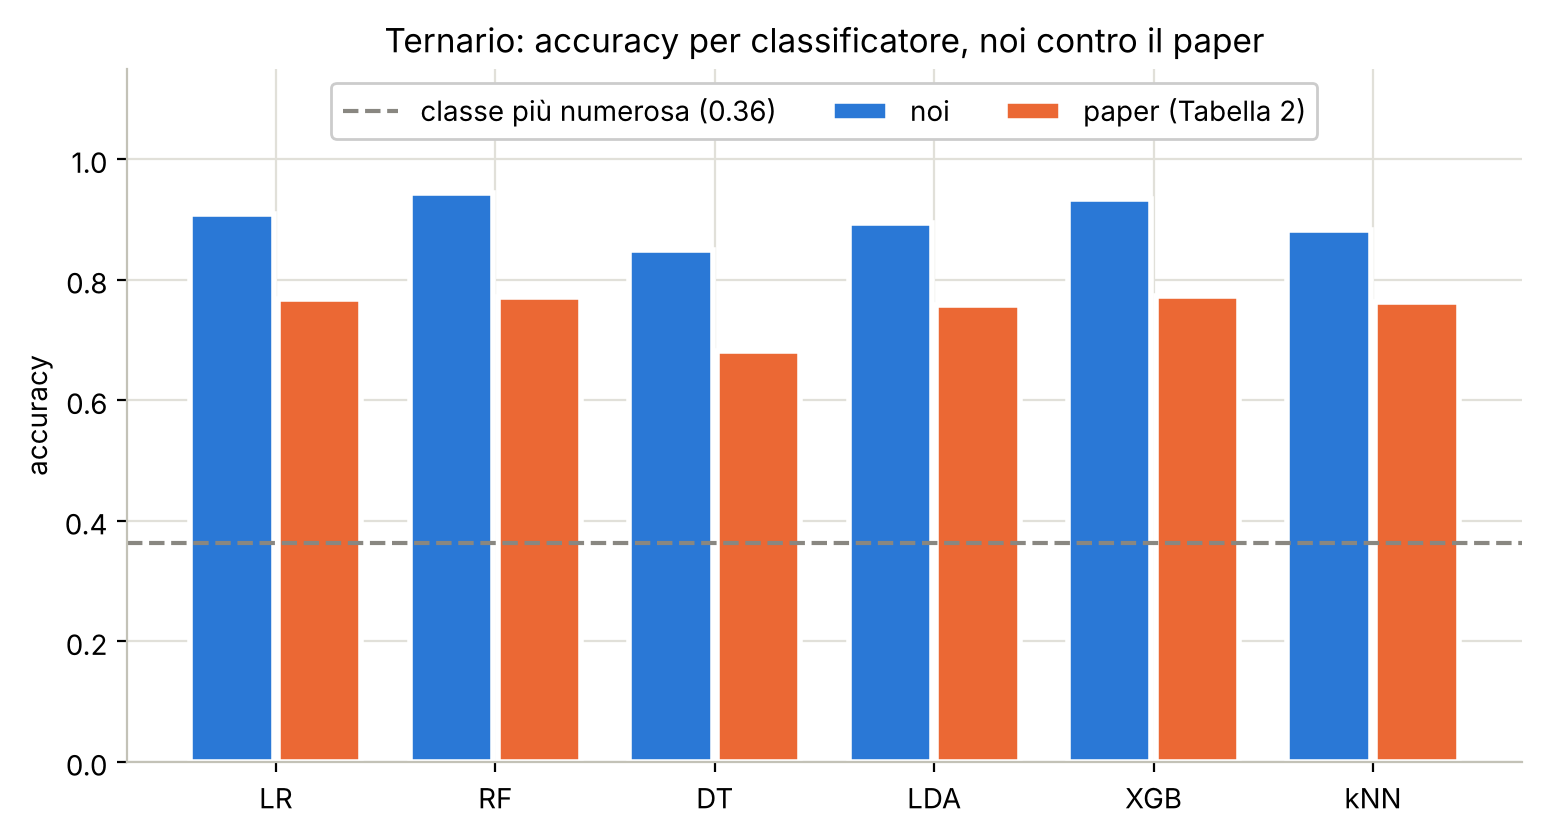

In [13]:
nomi = list(paper.keys())
noi = [risultati.loc[risultati["modello"] == n, "acc_media"].iloc[0] for n in nomi]
x = np.arange(len(nomi))
minimo = y.value_counts(normalize=True).max()

plt.figure(figsize=(9, 4.5))
plt.bar(x - 0.2, noi, width=0.38, color=BLU, edgecolor="white", linewidth=2, label="noi")
plt.bar(x + 0.2, [paper[n] for n in nomi], width=0.38, color=ARANCIO, edgecolor="white", linewidth=2, label="paper (Tabella 2)")
plt.axhline(minimo, color=GRIGIO, linestyle="--", linewidth=1.5, label=f"classe più numerosa ({minimo:.2f})")
plt.xticks(x, nomi)
plt.ylim(0, 1.15)
plt.ylabel("accuracy")
plt.title("Ternario: accuracy per classificatore, noi contro il paper")
plt.legend(loc="upper center", ncol=3, framealpha=1)
plt.show()

# Parte 3 — Dove sbaglia

## Fase 13 — Previsioni di Random Forest
La previsione di ogni riga quando la sua persona era lasciata fuori.

In [14]:
from sklearn.model_selection import cross_val_predict

rf = RandomForestClassifier(n_estimators=100, random_state=42)
previsioni = cross_val_predict(rf, X, y, groups=gruppi, cv=LeaveOneGroupOut())
tabella["previsto"] = previsioni
tabella["giusto"] = tabella["previsto"] == tabella["classe"]
print("Accuracy complessiva:", round(tabella["giusto"].mean(), 3))

Accuracy complessiva: 0.943


## Fase 14 — Matrice di confusione
Ogni riga è la classe vera, in percentuale: la diagonale sono le righe indovinate. La domanda chiave è quanto si confondono riposo e stress cognitivo.

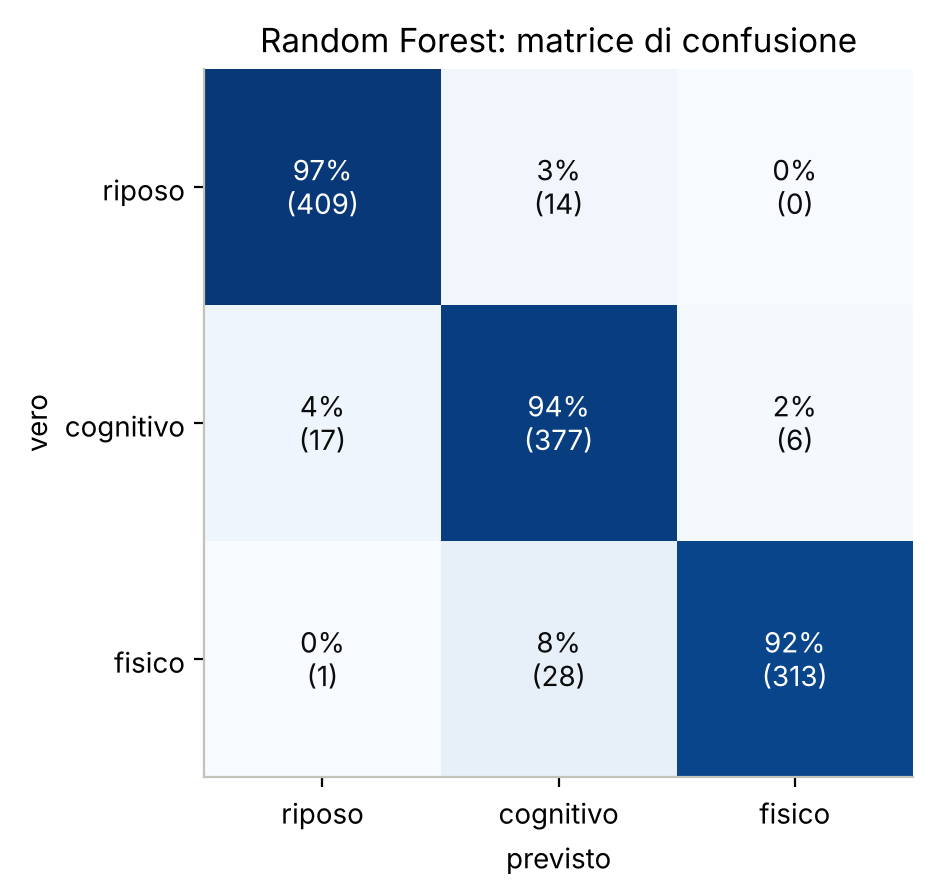

In [15]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y, previsioni)
cm_perc = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(5.5, 4.6))
plt.imshow(cm_perc, cmap="Blues", vmin=0, vmax=1)
plt.grid(False)
for i in range(3):
    for j in range(3):
        plt.text(j, i, f"{cm_perc[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center",
                 color="white" if cm_perc[i, j] > 0.5 else "#0b0b0b")
plt.xticks(range(3), nomi_classi)
plt.yticks(range(3), nomi_classi)
plt.xlabel("previsto")
plt.ylabel("vero")
plt.title("Random Forest: matrice di confusione")
plt.show()

## Fase 15 — Accuracy per persona
Una barra per persona esclusa. In arancione `ddca342b`, il braccialetto girato: con la correzione degli assi dovrebbe andare come gli altri.

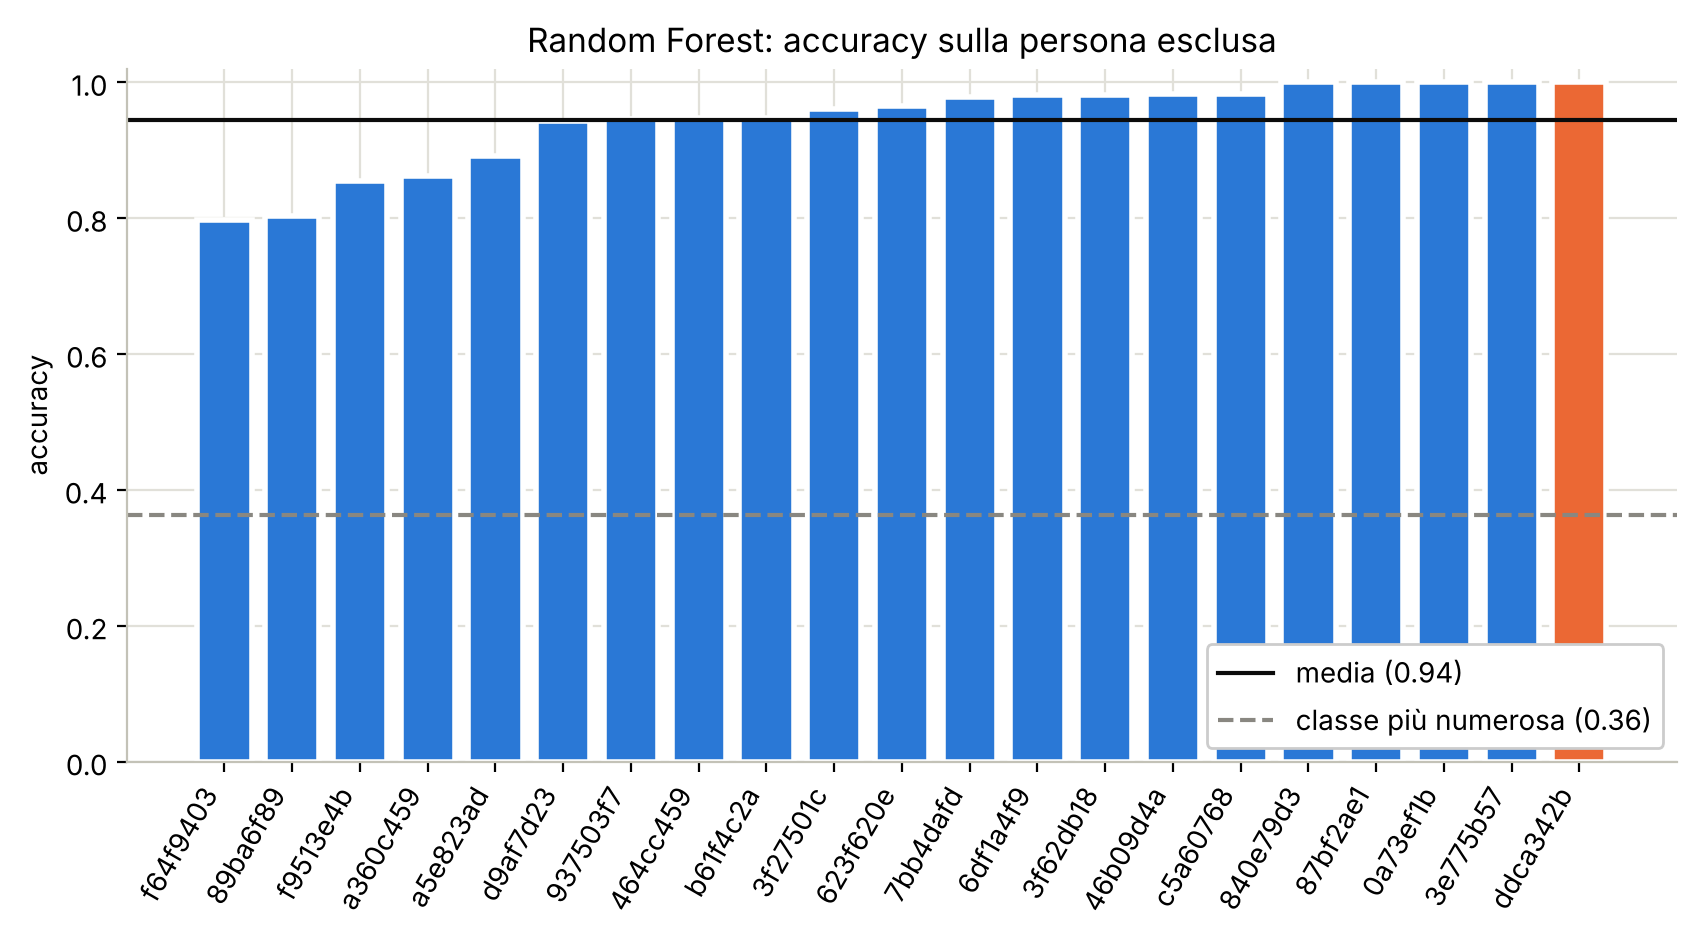

In [16]:
acc_persona = tabella.groupby(tabella["persona"].str[:8])["giusto"].mean().sort_values()
colori = [ARANCIO if p == "ddca342b" else BLU for p in acc_persona.index]

plt.figure(figsize=(10, 4.5))
plt.bar(acc_persona.index, acc_persona.values, color=colori, edgecolor="white", linewidth=2)
plt.axhline(acc_persona.mean(), color="#0b0b0b", linewidth=1.5, label=f"media ({acc_persona.mean():.2f})")
plt.axhline(minimo, color=GRIGIO, linestyle="--", linewidth=1.5, label=f"classe più numerosa ({minimo:.2f})")
plt.legend(loc="lower right", framealpha=1)
plt.xticks(rotation=60, ha="right")
plt.ylim(0, 1.02)
plt.ylabel("accuracy")
plt.title("Random Forest: accuracy sulla persona esclusa")
plt.show()

# Parte 4 — Ablation

## Fase 16 — Gruppi di feature
Cinque gruppi. Si toglie un gruppo intero e non una feature sola: std e varianza dello stesso asse contengono quasi la stessa informazione, quindi togliendone una il modello userebbe l'altra.

In [17]:
gruppi_feature = {
    "battito": ["bpm"],
    "sudore": ["stress_skin"],
    "temperatura": ["temp_sk1"],
    "postura (medie acc)": ["accX_mean", "accY_mean", "accZ_mean"],
    "agitazione (std e var acc)": ["accX_std", "accX_var", "accY_std", "accY_var",
                                   "accZ_std", "accZ_var"],
}
fisiologia = ["bpm", "stress_skin", "temp_sk1"]
movimento = [col for col in colonne if col.startswith("acc")]

## Fase 17 — Livello A: tutte, solo fisiologia, solo movimento
Sei classificatori per tre insiemi, accanto alla Tabella 2 del paper. Circa un minuto.

In [18]:
paper_gruppi = pd.DataFrame({
    "tutte":            {"LR": 0.769, "RF": 0.772, "DT": 0.682, "LDA": 0.758, "XGB": 0.773, "kNN": 0.763},
    "solo fisiologia":  {"LR": 0.631, "RF": 0.658, "DT": 0.628, "LDA": 0.645, "XGB": 0.651, "kNN": 0.627},
    "solo movimento":   {"LR": 0.726, "RF": 0.687, "DT": 0.686, "LDA": 0.730, "XGB": 0.749, "kNN": 0.787},
}).T

insiemi = {"tutte": colonne, "solo fisiologia": fisiologia, "solo movimento": movimento}
livello_a = pd.DataFrame(index=insiemi, columns=list(modelli), dtype=float)
for nome_insieme in insiemi:
    for nome in modelli:
        livello_a.loc[nome_insieme, nome] = valuta(modelli[nome], X[insiemi[nome_insieme]], y, gruppi)[0]

print("Noi:")
print(livello_a.round(2))
print("\nNoi − paper:")
print((livello_a - paper_gruppi).round(2))

Noi:
                   LR    RF    DT   LDA   XGB   kNN
tutte            0.91  0.94  0.85  0.89  0.93  0.88
solo fisiologia  0.77  0.74  0.67  0.74  0.73  0.73
solo movimento   0.85  0.90  0.81  0.85  0.90  0.86

Noi − paper:
                   LR    RF    DT   LDA   XGB   kNN
tutte            0.14  0.17  0.17  0.14  0.16  0.12
solo fisiologia  0.14  0.08  0.04  0.09  0.08  0.11
solo movimento   0.12  0.21  0.12  0.12  0.15  0.07


## Fase 18 — Livello B: togli un gruppo alla volta
Random Forest. Per ogni prova: accuracy e quante righe di ogni classe vengono riconosciute (recall per classe).

In [19]:
from sklearn.metrics import recall_score

def prova(colonne_usate):
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    previsto = cross_val_predict(rf, X[colonne_usate], y, groups=gruppi, cv=LeaveOneGroupOut())
    riga = {"accuracy": accuracy_score(y, previsto)}
    richiamo = recall_score(y, previsto, average=None)
    for k in range(3):
        riga[nomi_classi[k]] = richiamo[k]
    return riga

righe = {"tutte": prova(colonne)}
for nome_gruppo in gruppi_feature:
    rimaste = [col for col in colonne if col not in gruppi_feature[nome_gruppo]]
    righe["senza " + nome_gruppo] = prova(rimaste)
righe["solo fisiologia"] = prova(fisiologia)
righe["solo movimento"] = prova(movimento)

livello_b = pd.DataFrame(righe).T
livello_b.round(2)

,accuracy,riposo,cognitivo,fisico
tutte,0.94,0.97,0.94,0.92
senza battito,0.90,0.93,0.88,0.88
senza sudore,0.93,0.96,0.93,0.90
senza temperatura,0.93,0.96,0.92,0.90
senza postura (medie acc),0.88,0.95,0.81,0.87
senza agitazione (std e var acc),0.89,0.96,0.85,0.86
solo fisiologia,0.74,0.91,0.65,0.62
solo movimento,0.90,0.93,0.87,0.88


## Fase 19 — Grafico dell'ablation
Quanto cala il riconoscimento di ogni classe togliendo un gruppo, rispetto a tutte le feature.

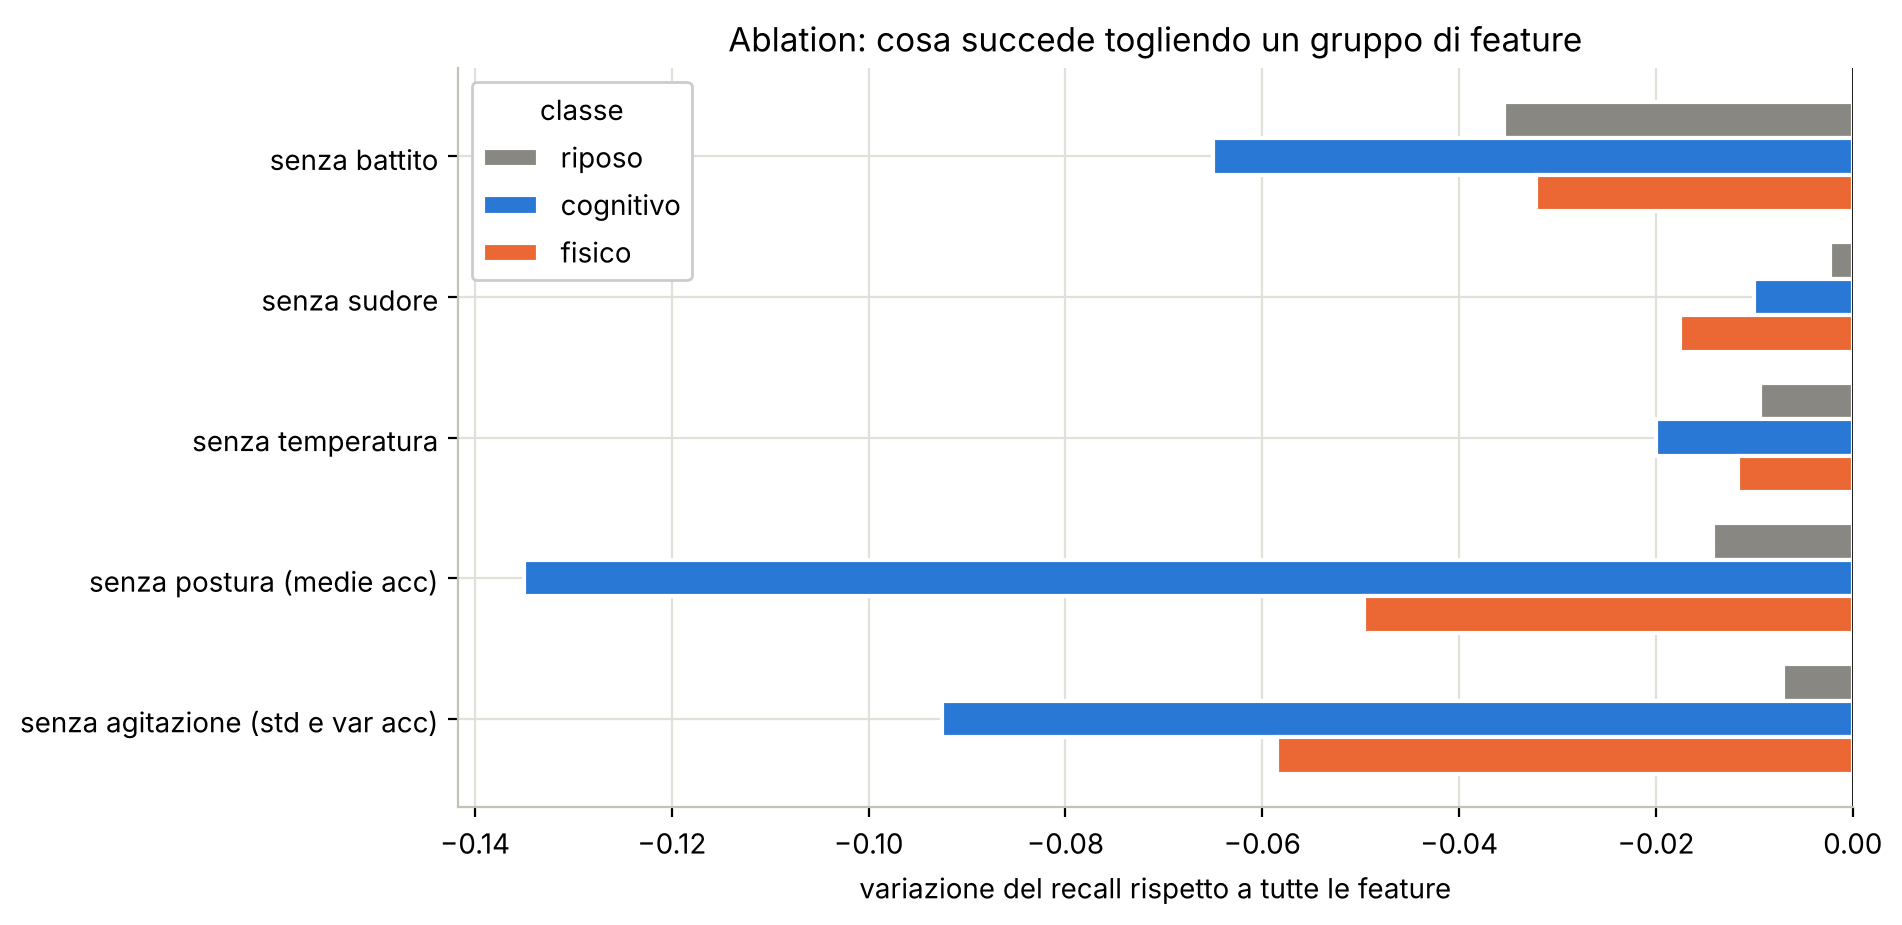

In [20]:
calo = livello_b[nomi_classi].drop(["tutte", "solo fisiologia", "solo movimento"]) - livello_b.loc["tutte", nomi_classi]
y_pos = np.arange(len(calo))

plt.figure(figsize=(9, 4.8))
for k, (classe, colore) in enumerate(zip(nomi_classi, [GRIGIO, BLU, ARANCIO])):
    plt.barh(y_pos + (k - 1) * 0.26, calo[classe], height=0.26, color=colore, edgecolor="white", linewidth=1.5, label=classe)
plt.axvline(0, color="#0b0b0b", linewidth=1)
plt.yticks(y_pos, calo.index)
plt.gca().invert_yaxis()
plt.xlabel("variazione del recall rispetto a tutte le feature")
plt.title("Ablation: cosa succede togliendo un gruppo di feature")
plt.legend(title="classe", loc="upper left", framealpha=1)
plt.show()

# Parte 5 — Rete neurale (MLP)

## Fase 20 — MLP
Una rete piccola con due strati nascosti (64 e 32 neuroni). I dati sono già normalizzati per persona. Stessa validazione dei classificatori.

In [21]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, early_stopping=True, random_state=42)
a, a_sd, f, f_sd = valuta(mlp, X, y, gruppi)
print(f"MLP: accuracy {a:.2f} ± {a_sd:.2f} | F1 {f:.2f} ± {f_sd:.2f}")

MLP: accuracy 0.88 ± 0.11 | F1 0.88 ± 0.11


## Fase 21 — MLP accanto ai classificatori
La stessa tabella della Fase 10, con la MLP in fondo.

In [22]:
confronto = risultati[["modello", "accuracy", "F1", "acc_media"]].copy()
confronto.loc[len(confronto)] = {"modello": "MLP", "accuracy": f"{a:.2f} ± {a_sd:.2f}",
                                 "F1": f"{f:.2f} ± {f_sd:.2f}", "acc_media": a}
confronto.sort_values("acc_media", ascending=False)

,modello,accuracy,F1,acc_media
1,RF,0.94 ± 0.06,0.94 ± 0.06,0.943981
4,XGB,0.93 ± 0.05,0.93 ± 0.05,0.934327
0,LR,0.91 ± 0.08,0.91 ± 0.08,0.909595
3,LDA,0.89 ± 0.07,0.89 ± 0.07,0.894926
5,kNN,0.88 ± 0.10,0.88 ± 0.10,0.883525
6,MLP,0.88 ± 0.11,0.88 ± 0.11,0.880579
2,DT,0.85 ± 0.10,0.84 ± 0.11,0.849001


## Note
- Classi come il paper: riposo / calcolo + discorso / corsa
- Solo le 4 fasi principali: pause fra i compiti, preparazione del discorso e recupero finale restano fuori
- `a5e823ad`: del riposo di 82 minuti si tengono gli ultimi 10 (Fase 1)
- `ddca342b`: media di accY e accZ con il segno invertito (`ASSI_GIRATI`, Fase 0); per i dati originali basta svuotare il dizionario
- Ablation per gruppi, non per singola feature: feature collegate si sostituiscono a vicenda
- Riferimento minimo: rispondere sempre la classe più numerosa
- MLP: parametri standard, senza ricerca degli iperparametri